In [1]:
import pandas as pd

import numpy as np

from statsmodels.tsa.arima.model import ARIMA

from statsmodels.tsa.stattools import adfuller

from statsmodels.graphics.tsaplots import plot_acf,plot_pacf

from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

In [2]:


data = {
    "Month": pd.date_range(start="2020-01-01", periods=36, freq="MS"),
    "Sales": [
        120, 125, 128, 135, 132, 140,
        145, 150, 148, 155, 160, 165,
        170, 168, 175, 180, 178, 185,
        190, 195, 193, 200, 205, 210,
        215, 212, 220, 225, 223, 230,
        235, 240, 238, 245, 250, 255
    ]
}

df = pd.DataFrame(data)

print(df.head())

       Month  Sales
0 2020-01-01    120
1 2020-02-01    125
2 2020-03-01    128
3 2020-04-01    135
4 2020-05-01    132


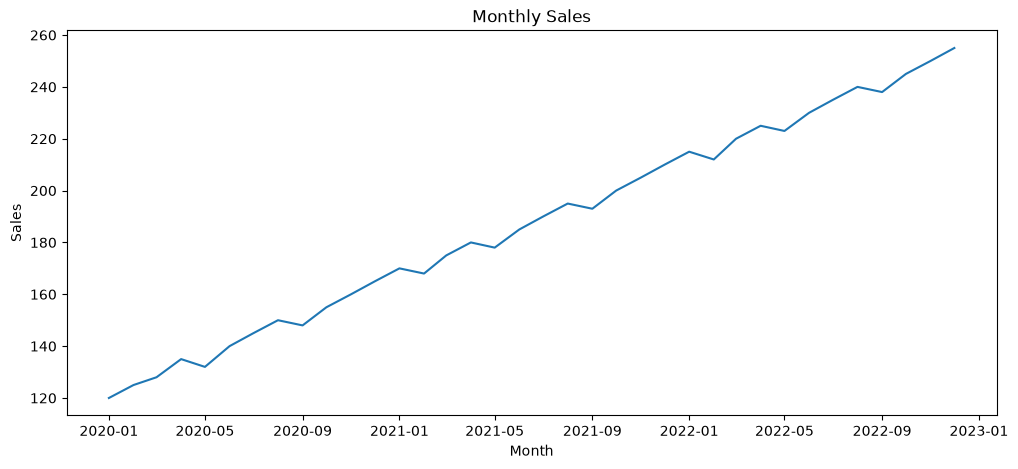

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(df["Month"], df["Sales"])
plt.xlabel("Month")
plt.ylabel("Sales")
plt.title("Monthly Sales")
plt.show()

In [4]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(df["Sales"])



print("ADF Statistic:", f"{result[0]:.6f}")
print("p-value:", f"{result[1]:.6f}")

ADF Statistic: -0.577951
p-value: 0.875887


        Month  Sales  Sales_diff
0  2020-01-01    120         NaN
1  2020-02-01    125         5.0
2  2020-03-01    128         3.0
3  2020-04-01    135         7.0
4  2020-05-01    132        -3.0
5  2020-06-01    140         8.0
6  2020-07-01    145         5.0
7  2020-08-01    150         5.0
8  2020-09-01    148        -2.0
9  2020-10-01    155         7.0
10 2020-11-01    160         5.0
11 2020-12-01    165         5.0
12 2021-01-01    170         5.0
13 2021-02-01    168        -2.0
14 2021-03-01    175         7.0
15 2021-04-01    180         5.0
16 2021-05-01    178        -2.0
17 2021-06-01    185         7.0
18 2021-07-01    190         5.0
19 2021-08-01    195         5.0
20 2021-09-01    193        -2.0
21 2021-10-01    200         7.0
22 2021-11-01    205         5.0
23 2021-12-01    210         5.0
24 2022-01-01    215         5.0
25 2022-02-01    212        -3.0
26 2022-03-01    220         8.0
27 2022-04-01    225         5.0
28 2022-05-01    223        -2.0
29 2022-06

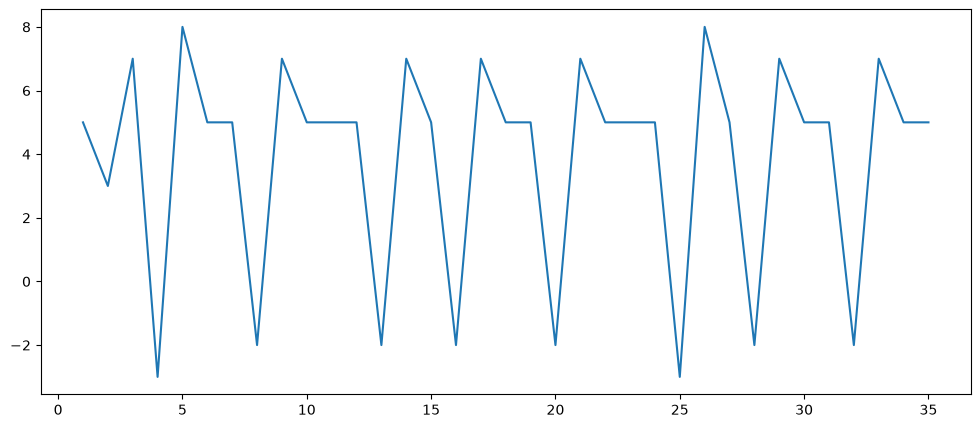

In [5]:
df["Sales_diff"] = df["Sales"].diff()
print(df)
df["Sales_diff"].dropna().plot(figsize=(12,5))
plt.show()
df=df.dropna()

In [6]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(df["Sales_diff"].dropna())

print("ADF Statistic:", f"{result[0]:.6f}")
print("p-value:", f"{result[1]:.6f}")

ADF Statistic: -7.997173
p-value: 0.000000


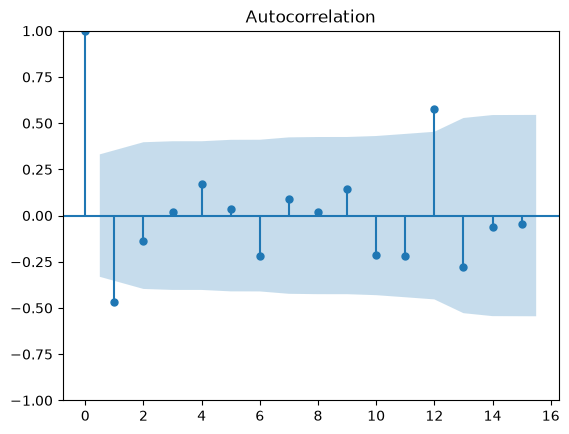

In [7]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(df["Sales_diff"].dropna(), lags=15)
plt.show()

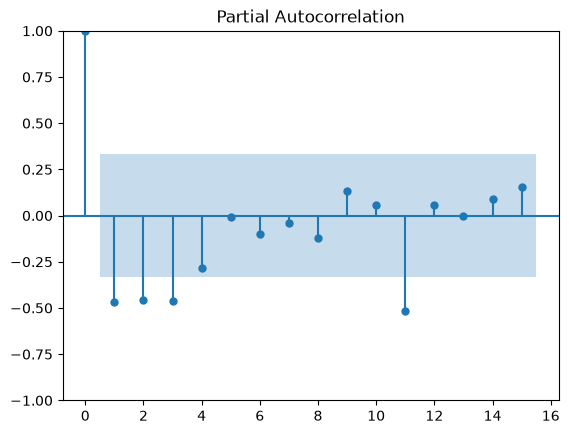

In [8]:
from statsmodels.graphics.tsaplots import plot_pacf

plot_pacf(df["Sales_diff"].dropna(), lags=15, method="ywm")
plt.show()

In [9]:
train_size=int(len(df)*0.8)
print(train_size)
train=df['Sales'][:train_size]
test=df['Sales'][train_size:]

28


In [10]:
model=ARIMA(train,order=(1,1,1))

model_fit=model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   28
Model:                 ARIMA(1, 1, 1)   Log Likelihood                 -75.566
Date:                Wed, 21 Oct 2026   AIC                            157.133
Time:                        17:17:43   BIC                            161.021
Sample:                             0   HQIC                           158.289
                                 - 28                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.0000      0.001    991.881      0.000       0.998       1.002
ma.L1         -0.9980      0.442     -2.256      0.024      -1.865      -0.131
sigma2        14.0332      0.032    440.354      0.0

In [13]:
forecast=model_fit.forecast(steps=len(test))

comparison=pd.DataFrame({
    'Actual':test,
    'Forecast':forecast
})
print(comparison)

    Actual    Forecast
29     230  226.485179
30     235  229.970349
31     240  233.455512
32     238  236.940666
33     245  240.425813
34     250  243.910951
35     255  247.396081


In [14]:
mae=mean_absolute_error(test,forecast)
mse=mean_squared_error(test,forecast)
rmse=np.sqrt(mse)

print('MAE :',mae)
print('MSE :',mse)
print('RMSE:',rmse)

MAE : 4.916492788840254
MSE : 28.2033086458079
RMSE: 5.310678736829022


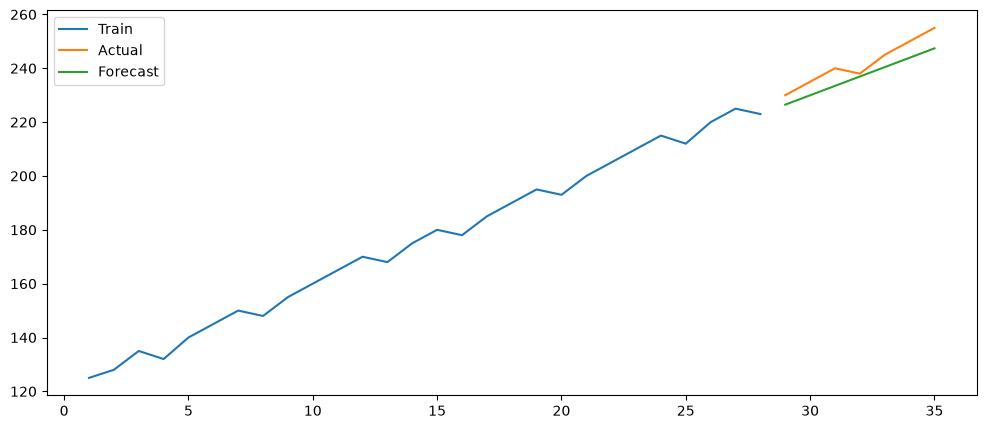

In [15]:
plt.figure(figsize=(12,5))
plt.plot(train,label='Train')
plt.plot(test,label='Actual')
plt.plot(forecast,label='Forecast')
plt.legend()
plt.show()

In [16]:
future=model_fit.forecast(steps=30)

print(future)

future.to_csv('future_prediction.csv')
print('Future predictions saved')

29    226.485179
30    229.970349
31    233.455512
32    236.940666
33    240.425813
34    243.910951
35    247.396081
36    250.881204
37    254.366318
38    257.851424
39    261.336522
40    264.821612
41    268.306694
42    271.791768
43    275.276834
44    278.761892
45    282.246942
46    285.731984
47    289.217018
48    292.702044
49    296.187061
50    299.672071
51    303.157073
52    306.642066
53    310.127052
54    313.612029
55    317.096999
56    320.581960
57    324.066913
58    327.551859
Name: predicted_mean, dtype: float64
Future predictions saved
